In [ ]:
#Q2
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

In [ ]:
mean = [0, 0]

In [ ]:
cov = [
    [1, 0.8],
    [0.8, 1]
]

In [ ]:
X = np.random.multivariate_normal(mean, cov, 500)

In [ ]:
feature_1 = X[:, 0]
feature_2 = X[:, 1]

In [ ]:
correlation = np.corrcoef(feature_1, feature_2)[0, 1]

print("Correlation coefficient:", correlation)


Correlation coefficient: 0.7907507887090052


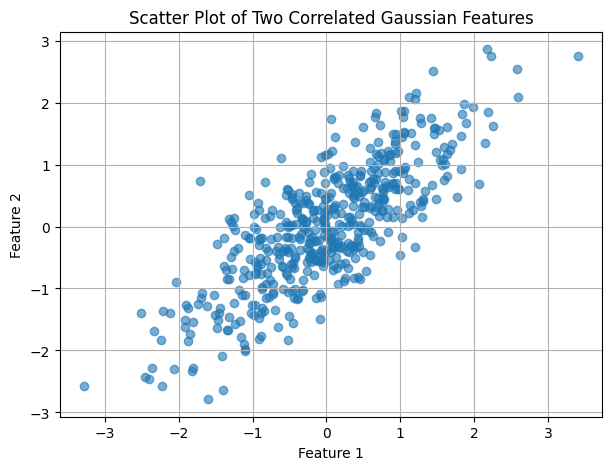

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(feature_1, feature_2, alpha=0.6)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Scatter Plot of Two Correlated Gaussian Features")
plt.grid(True)
plt.show()

In [ ]:
#Q3
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)

In [ ]:
mean = [0, 0]

In [ ]:
cov = [
    [1, 0.8],
    [0.8, 1]
]

In [ ]:
X = np.random.multivariate_normal(mean, cov, 500)

print("Original data shape:", X.shape)

Original data shape: (500, 2)


In [ ]:
mean_vector = np.mean(X, axis=0)

In [ ]:
X_centered = X - mean_vector

print("Mean vector:", mean_vector)

Mean vector: [-0.01450426  0.00767147]


In [ ]:
cov_matrix = np.cov(X_centered, rowvar=False)

print("Covariance matrix:")
print(cov_matrix)

Covariance matrix:
[[0.92486292 0.74324047]
 [0.74324047 0.95521704]]


In [ ]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

In [ ]:
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[1.68343539 0.19664457]

Eigenvectors:
[[ 0.69985146 -0.71428841]
 [ 0.71428841  0.69985146]]


In [ ]:
PC1 = eigenvectors[:, 0]

In [ ]:
principal_components = eigenvectors[:, :2]

print("First Principal Component:")
print(PC1)

First Principal Component:
[0.69985146 0.71428841]


In [ ]:
explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)

print("Explained variance ratio:")
print(explained_variance_ratio)

Explained variance ratio:
[0.89540627 0.10459373]


In [ ]:
plt.figure(figsize=(8, 6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

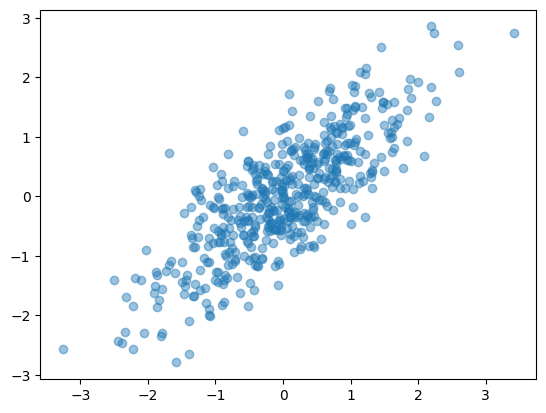

In [ ]:
plt.scatter(
    X_centered[:, 0],
    X_centered[:, 1],
    alpha=0.45,
    label="Centered data"
)

/tmp/ipykernel_993/1621185662.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


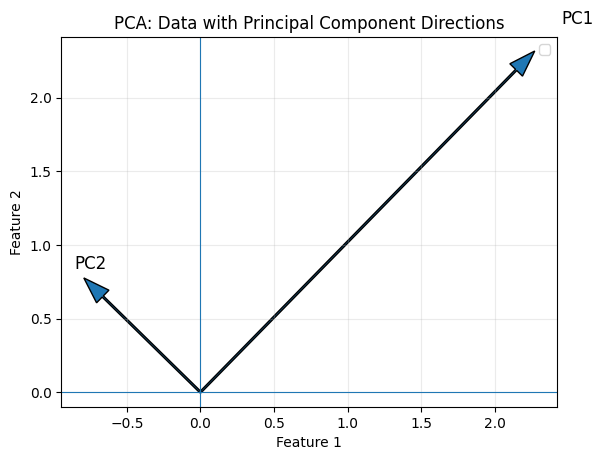

In [ ]:
for i in range(2):
    direction = (
        eigenvectors[:, i]
        * np.sqrt(eigenvalues[i])
        * 2.5
    )

    plt.arrow(
        0, 0,
        direction[0],
        direction[1],
        width=0.012,
        head_width=0.12,
        length_includes_head=True
    )

    plt.text(
        direction[0] * 1.08,
        direction[1] * 1.08,
        f"PC{i+1}",
        fontsize=12
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PCA: Data with Principal Component Directions")
plt.legend()
plt.grid(True, alpha=0.25)
plt.axis("equal")
plt.show()

In [ ]:
#Q4
explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)

In [ ]:
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Explained variance ratio:")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"PC{i+1}: {ratio:.4f} ({ratio*100:.2f}%)")

print("\nCumulative explained variance:")
for i, value in enumerate(cumulative_variance):
    print(f"PC{i+1}: {value:.4f} ({value*100:.2f}%)")

Explained variance ratio:
PC1: 0.8954 (89.54%)
PC2: 0.1046 (10.46%)

Cumulative explained variance:
PC1: 0.8954 (89.54%)
PC2: 1.0000 (100.00%)


Trade-off between variance and dimensionality reduction
-PC1 keeps about 89.54% of the info in the dataset, so it represents most of the variation
-by using only PC1 we reduce data from 2D TO 1D making it simpler to work with
-the downside is that we end up losing about 10.46% of the info represented by PC2
-if we keep both PC1 and PC2, we keep 100% variance but we do not end up reducing the dimensions
-so PCA is about finding a good balance between keeping imp info and making the data simpler
-in this particular case, keeping only PC1 seems reasonable because we keep almost 90% of the info while reducing the number of dimensions

https://chatgpt.com/share/6ac71270-f508-83e8-97c8-dbb3c3ccb0c6